# Clase 10


## 1 Introducción

En esta clase, seguiremos estudiando los árboles de decisión (Decision Trees o DTs) utilizando `Scikit-learn`.

## 2 DTs para el conjunto de datos 2D sintético

#### 1. Carga el conjunto de datos sintético `"sintetico_2d.csv"`. Este conjunto tiene dos características y una etiqueta de clase. Utiliza la función `scatter()` de matplotlib para graficar el conjunto de datos en un plano 2D y colorea los puntos en función de su etiqueta de clase.

          x         y  target
0  9.833469  0.319565       0
1  1.801045  8.705072       0
2  4.423918  3.488906       1
3  0.280730  2.689037       1
4  5.999494  9.167512       0


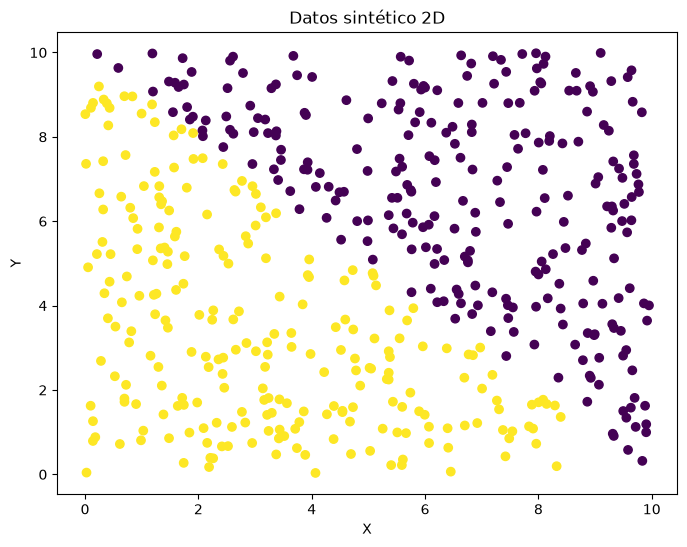

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

datos = pd.read_csv("sintetico_2d.csv")
print(datos.head())


plt.figure(figsize=(8, 6))

## utilizamos la funcione c que indica que color le corresponde a cada punto 
plt.scatter(datos["x"], datos["y"], c=datos["target"])
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Datos sintético 2D")
plt.show()

### 2. Construye un árbol de decisión simple utilizando el conjunto de datos completo y luego visualiza el modelo aprendido. ¿Qué está aprendiendo el árbol y por qué?


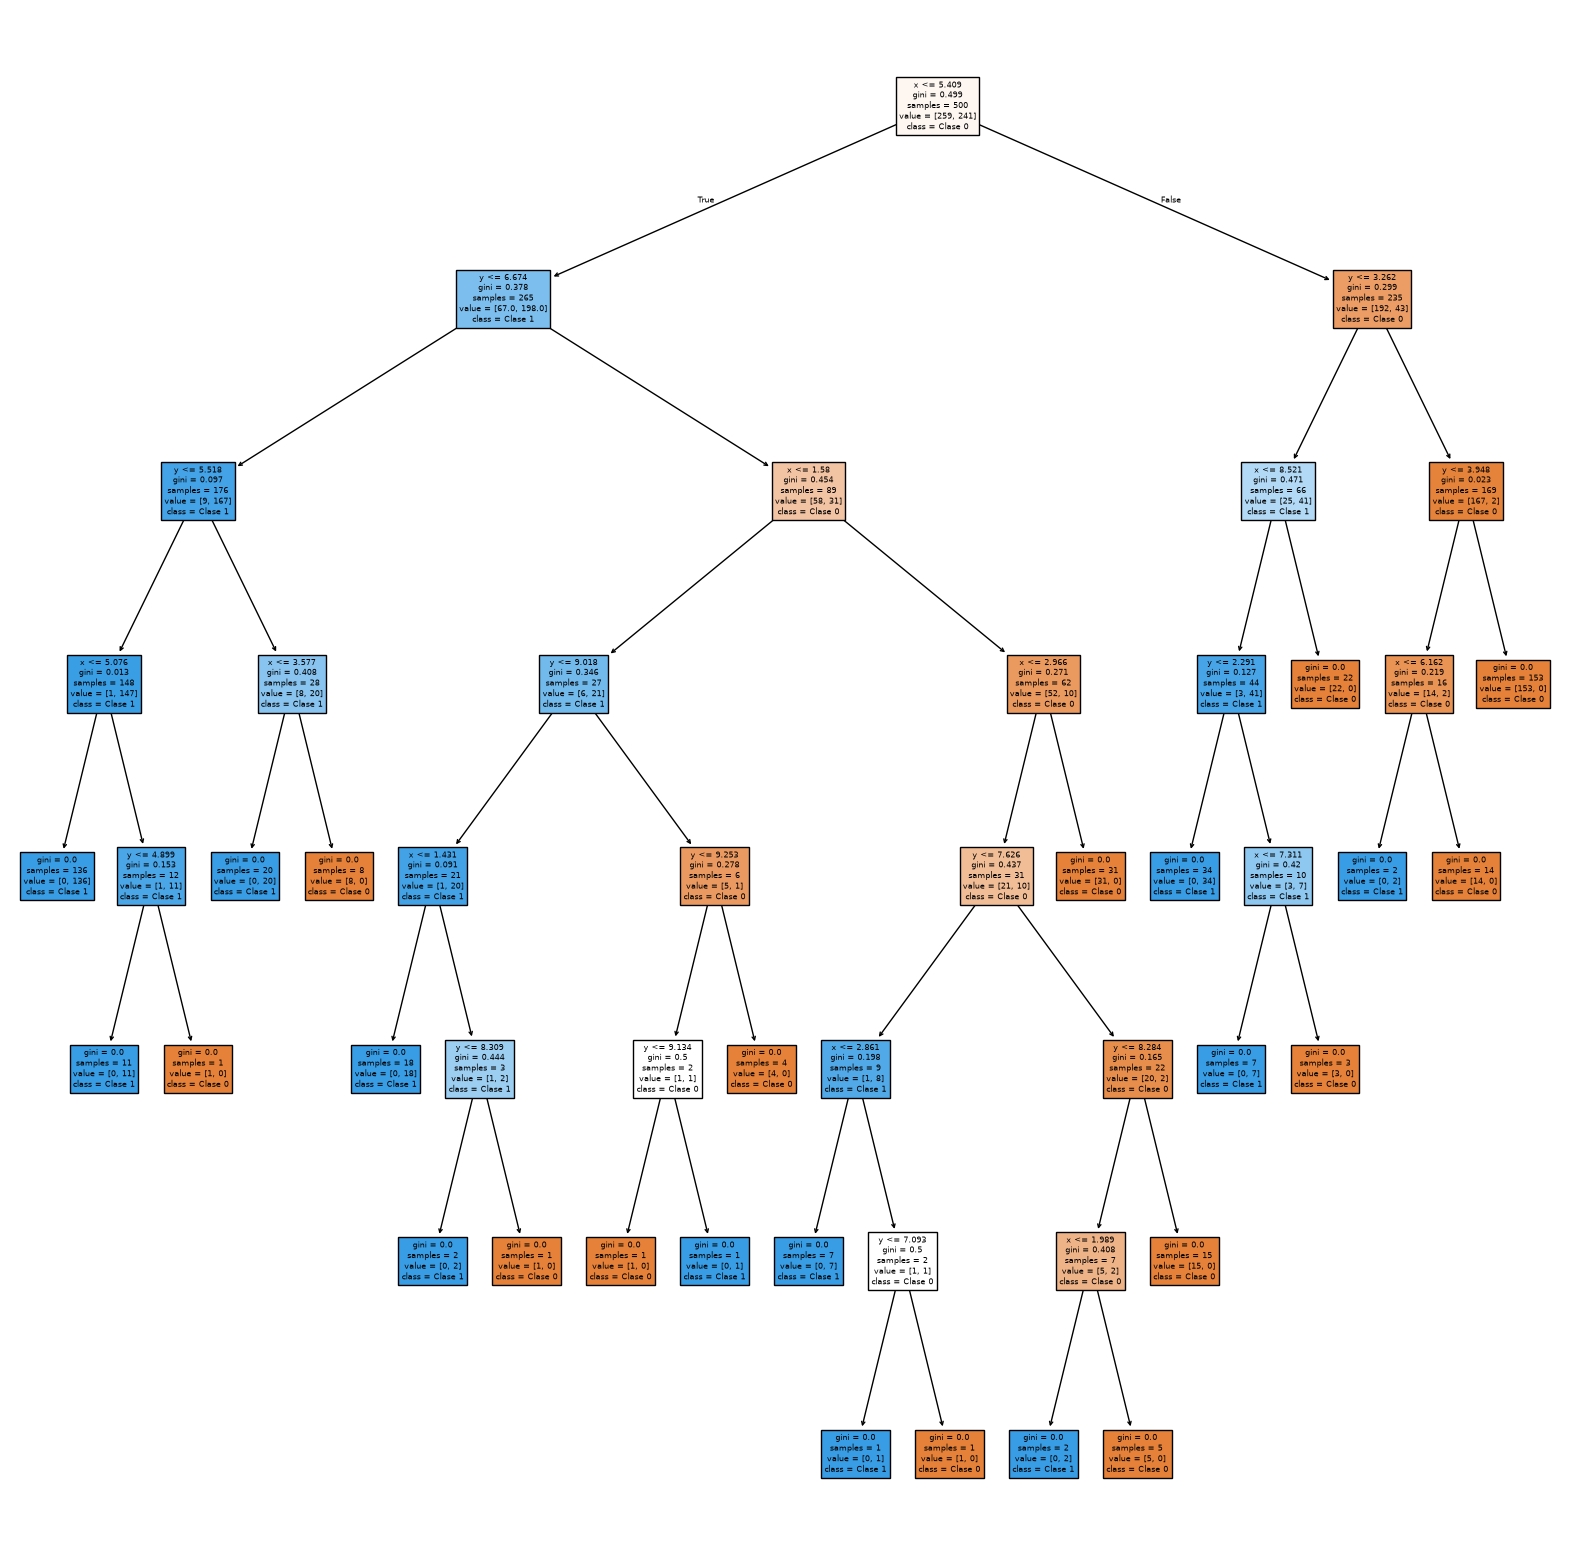

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

X = datos[["x", "y"]]
y = datos["target"]
clf = DecisionTreeClassifier()
clf.fit(X, y)

plt.figure(figsize=(20, 20))
plot_tree(clf,feature_names=["x", "y"],class_names=["Clase 0", "Clase 1"],filled=True)
plt.show()

El árbol de decisión va aprendiendo a separar los datos dependiendo de los valores de X y Y, de manera en que busca que los puntos de una misma clase queden agrupados tratando de que las clases se mezclen lo menos posible. Como podemos observar que los datos tienen una separación diagonal, el árbol necesita hacer varias divisiones horizontales y verticales para poder distinguir entre las dos clases.


### 3. Los árboles de decisión de `sklearn` almacenan, para cada división que realizan, la información sobre la característica que están usando para la división y el valor umbral usado en la comparación. Puedes encontrar esta información en `clf.tree_.feature` y `clf.tree_.threshold`. Con esta información, puedes tomar el código de `dibujar_divisiones.py` y graficar las fronteras de decisión (es decir, los umbrales de las características) aplicados por el árbol de decisión en el conjunto de datos. Idealmente, deberías tener un gráfico 2D con líneas verticales y horizontales que dividan el plano en subregiones (una para cada hoja del árbol).


In [3]:
print(clf.tree_.feature)
print(clf.tree_.threshold)

[ 0  1  1  0 -2  1 -2 -2  0 -2 -2  0  1  0 -2  1 -2 -2  1  1 -2 -2 -2  0
  1  0 -2  1 -2 -2  1  0 -2 -2 -2 -2  1  0  1 -2  0 -2 -2 -2  1  0 -2 -2
 -2]
[ 5.40876412  6.6744628   5.51829243  5.07607341 -2.          4.89870858
 -2.         -2.          3.57739341 -2.         -2.          1.57965869
  9.01819515  1.4306519  -2.          8.30936813 -2.         -2.
  9.253016    9.13419342 -2.         -2.         -2.          2.96561909
  7.62585855  2.86126113 -2.          7.09328413 -2.         -2.
  8.28434324  1.98910064 -2.         -2.         -2.         -2.
  3.26193082  8.52058029  2.29148185 -2.          7.31053472 -2.
 -2.         -2.          3.94774652  6.16223955 -2.         -2.
 -2.        ]


In [4]:
# codigo dibujar_divisiones.py
import numpy as np
import matplotlib.pyplot as plt


def dibujar_divisiones(features, thresholds, indice, x_min, x_max, y_min, y_max):
    feature = features[indice]
    umbral = thresholds[indice]

    if feature == -2:
        return 1

    if feature == 0:
        plt.axvline(x=umbral, ymin=y_min / 10, ymax=y_max / 10, color='red', linestyle='--')

        izquierda = (x_min, umbral, y_min, y_max)
        derecha   = (umbral, x_max, y_min, y_max)

    else:
        plt.axhline(y=umbral, xmin=x_min / 10, xmax=x_max / 10, color='blue', linestyle='--')

        izquierda = (x_min, x_max, y_min, umbral)
        derecha   = (x_min, x_max, umbral, y_max)

    offset_izq = dibujar_divisiones(features, thresholds, indice + 1, *izquierda)
    offset_der = dibujar_divisiones(features, thresholds, indice + offset_izq + 1, *derecha)

    return offset_izq + offset_der + 1

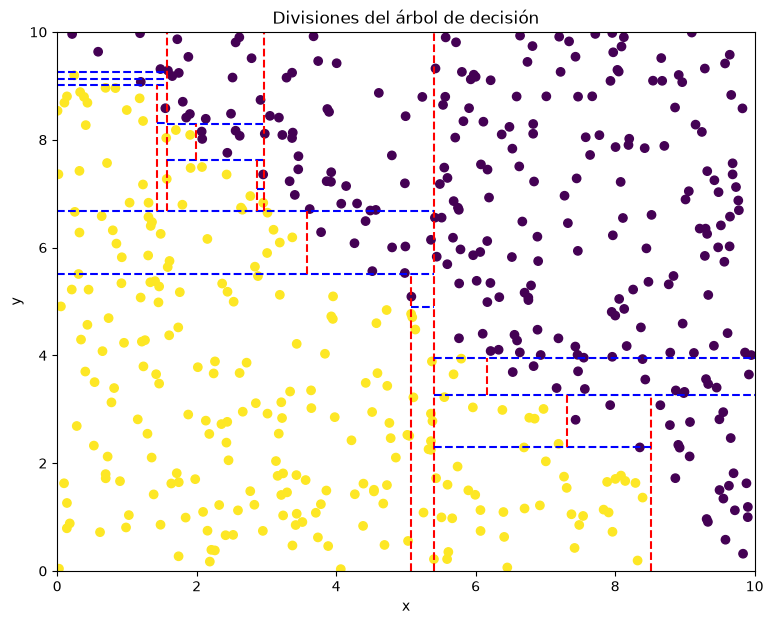

In [5]:

plt.figure(figsize=(9, 7))

plt.scatter(X["x"], X["y"], c=y)
plt.xlim(0, 10)
plt.ylim(0, 10)

dibujar_divisiones(clf.tree_.feature,clf.tree_.threshold,0, 0, 10, 0, 10)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Divisiones del árbol de decisión")
plt.show()


### 4. Identifica una **nueva variable muy simple** que se podría construir de las variables de entrada que permitiría al árbol de decisión aprender muy rápido de este problema.

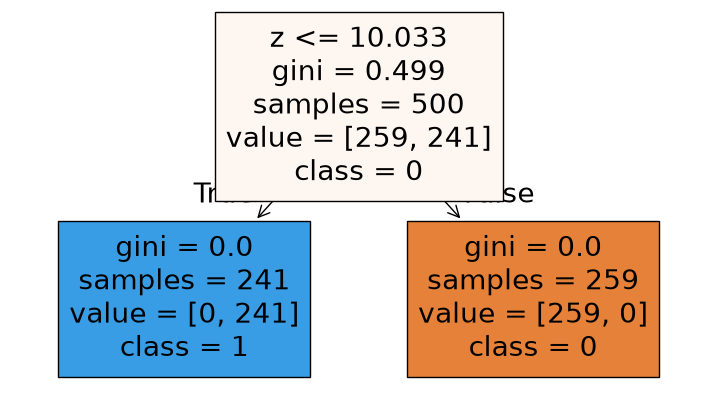

In [6]:
datos["z"] = datos["x"] + datos["y"]
datos.head()

X_nuevo = datos[["z"]]
y_nuevo = datos["target"]

clf_nuevo = DecisionTreeClassifier(random_state=123)
clf_nuevo.fit(X_nuevo, y_nuevo)

plt.figure(figsize=(9, 5))
plot_tree(clf_nuevo,feature_names=["z"],class_names=["0", "1"],filled=True)
plt.show()

## 3 DTs para el conjunto de lunas
 ### 1. Carga el conjunto de datos sintético de las lunas:
   Utiliza la función `scatter()` de matplotlib para graficar el conjunto de datos en un plano 2D y colorea los puntos en función de su etiqueta de clase.


(1000, 2)
(1000,)


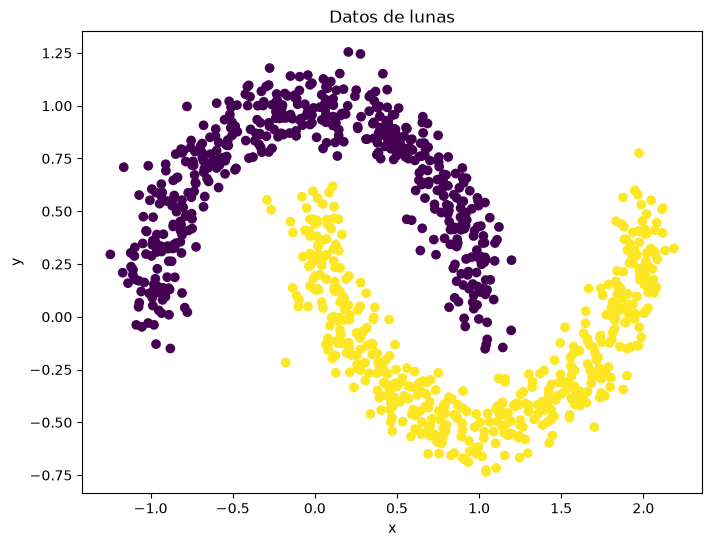

In [7]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.1, random_state=123)

print(X.shape)
print(y.shape)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datos de lunas")
plt.show()


###  2. Construye un árbol de decisión simple utilizando este conjunto de datos completo y visualízalo.


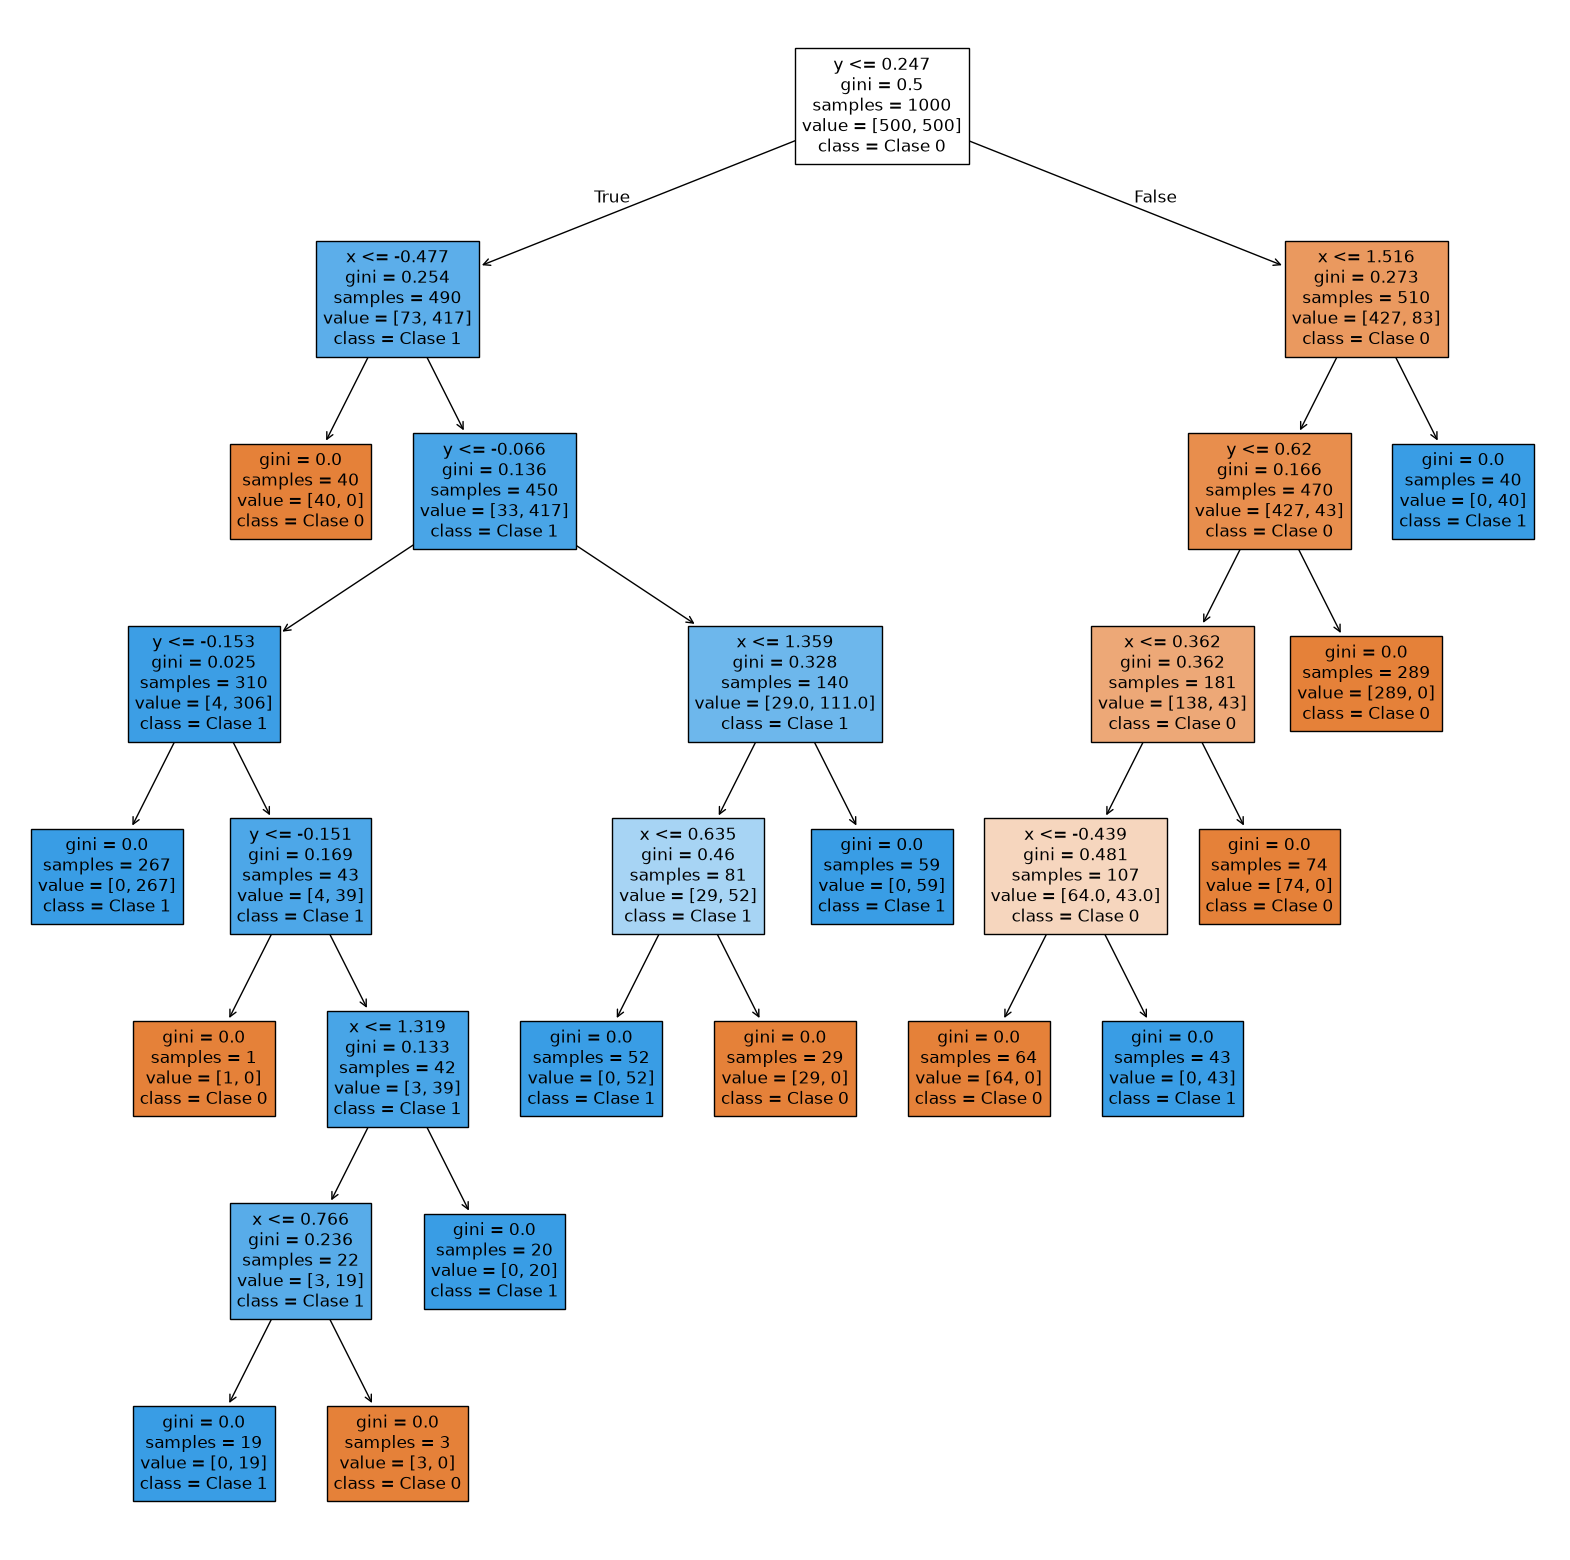

In [8]:
lunas_clf = DecisionTreeClassifier(random_state=123)
lunas_clf.fit(X, y)

plt.figure(figsize=(20, 20))
plot_tree(lunas_clf, feature_names=["x", "y"], class_names=["Clase 0", "Clase 1"], filled=True)
plt.show()


### 3. Ahora puedes tomar el código de `dibujar_frontera_decision.py` y graficar las fronteras de decisión.

In [9]:
#codigo dibujar_frontera_decision
import numpy as np
def dibujar_frontera_decision(clf, X, y, x_min, x_max, y_min, y_max):
    puntos_x = np.linspace(x_min, x_max, 300)
    puntos_y = np.linspace(y_min, y_max, 300)
    malla_x, malla_y = np.meshgrid(puntos_x, puntos_y)

    rejilla = np.c_[malla_x.ravel(), malla_y.ravel()]

    predicciones = clf.predict(rejilla).reshape(malla_x.shape)

    plt.contourf(malla_x, malla_y, predicciones, alpha=0.1)

    plt.scatter(X[:, 0], X[:, 1], c=y)

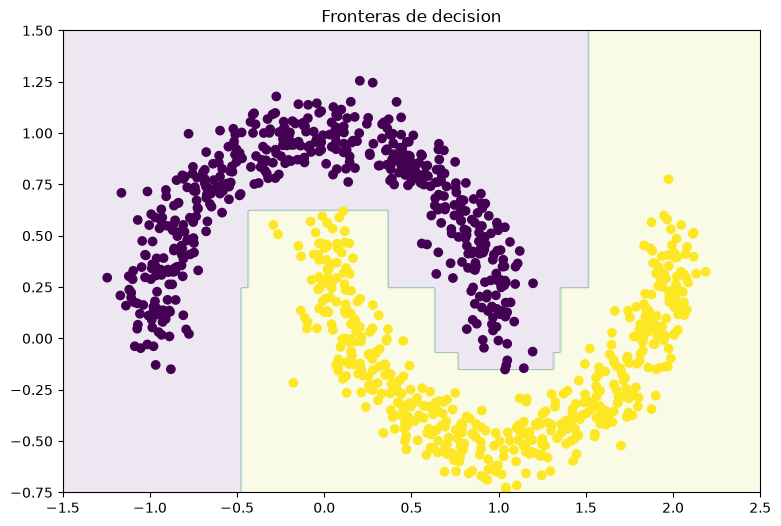

In [10]:
plt.figure(figsize=(9, 6))
dibujar_frontera_decision(lunas_clf, X, y, -1.5, 2.5, -0.75, 1.5)
plt.title("Fronteras de decision")
plt.show()


### 4. Cambia la cantidad de ruido (por ejemplo `noise=0.5`) en las lunas.

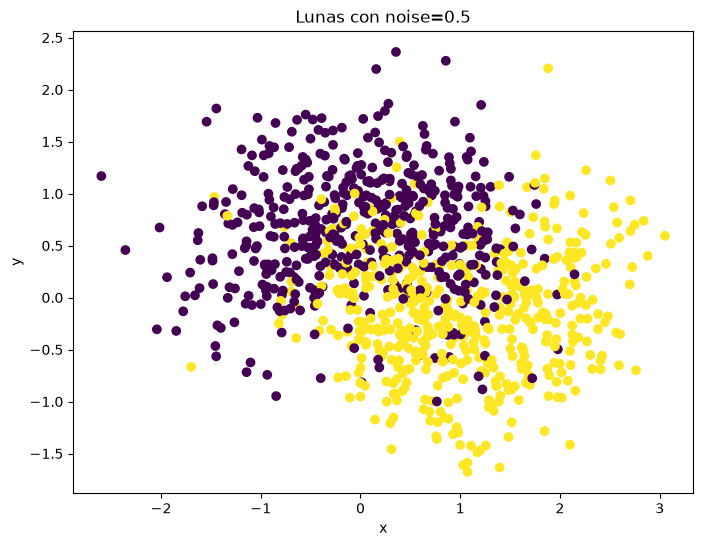

In [11]:
X_ruido, y_ruido = make_moons(n_samples=1000, noise=0.5, random_state=123)

plt.figure(figsize=(8, 6))
plt.scatter(X_ruido[:, 0], X_ruido[:, 1], c=y_ruido)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Lunas con noise=0.5")
plt.show()


### 5. Entrena un `DecisionTreeClassifier`, y compara la precisión en conjuntos de entrenamiento y prueba (80% entrenamiento, 20% test).

Precisión de entrenamiento: 1.0
Precisión de prueba: 0.75


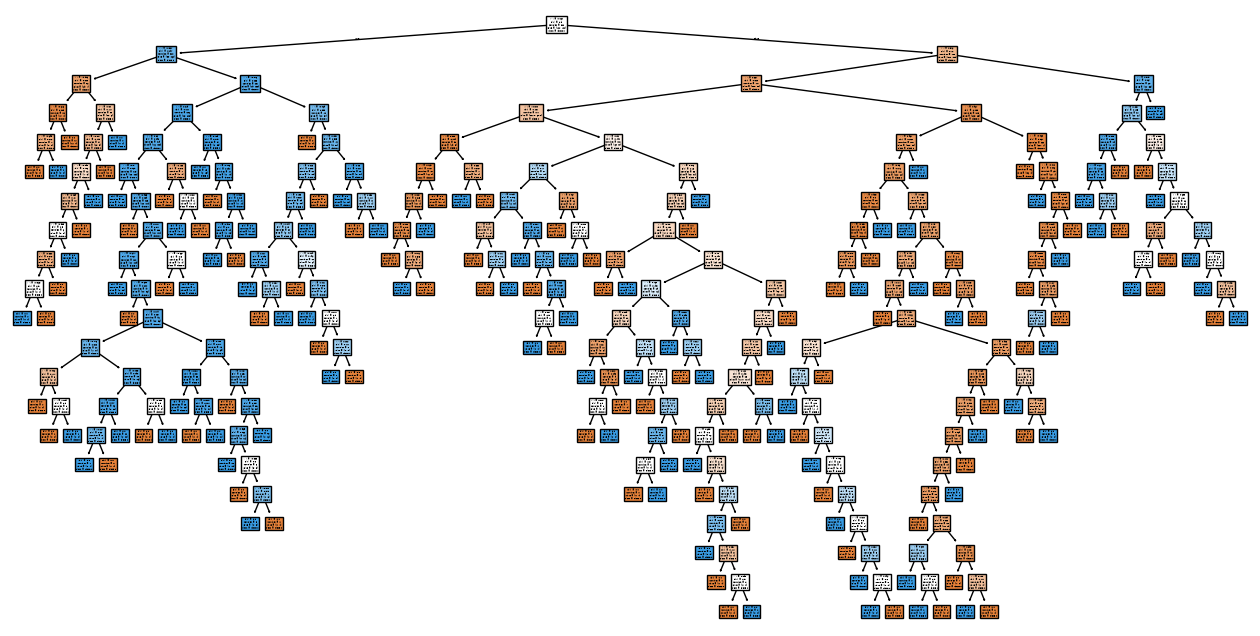

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_ruido, y_ruido, test_size=0.2, random_state=123, stratify=y_ruido)
clf_ruido = DecisionTreeClassifier(random_state=123)
clf_ruido.fit(X_train, y_train)
precision_train = clf_ruido.score(X_train, y_train)
precision_test = clf_ruido.score(X_test, y_test)

print("Precisión de entrenamiento:", precision_train)
print("Precisión de prueba:", precision_test)

plt.figure(figsize=(16, 8))
plot_tree(clf_ruido,feature_names=["x", "y"],class_names=["Clase 0", "Clase 1"],filled=True,)
plt.show()


###  6. Demuestra que estamos en un claro caso de sobreajuste (overfitting). Compara `accuracy_score` de conjuntos de entrenamiento y prueba.

In [13]:
from sklearn.metrics import accuracy_score

y_pred_train = clf_ruido.predict(X_train)
y_pred_test = clf_ruido.predict(X_test)

accuracy_train = accuracy_score(y_train, y_pred_train)
accuracy_test = accuracy_score(y_test, y_pred_test)

print("Accuracy entrenamiento:", accuracy_train)
print("Accuracy prueba:", accuracy_test)
print("Diferencia:", accuracy_train - accuracy_test)


Accuracy entrenamiento: 1.0
Accuracy prueba: 0.75
Diferencia: 0.25
